In [ ]:
%pip install -q requests pydantic python-dotenv pandas matplotlib numpy pymilvus pypdf trafilatura


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [26]:
import os, re, sys, json, time, hashlib, threading
from pathlib import Path
from dataclasses import dataclass, field
from concurrent.futures import ThreadPoolExecutor
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from pymilvus import MilvusClient
from trafilatura import extract


try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("OPENROUTER_API_KEY", UserSecretsClient().get_secret("OPENROUTER_API_KEY"))
except Exception:
    pass
assert os.getenv("OPENROUTER_API_KEY"), "нет ключа: положите его в .env рядом с ноутбуком или в Kaggle Secrets"

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}", "X-Title": "agents-course-seminar02"}
MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}
EMBED_MODEL, DIM = "openai/text-embedding-3-small", 512
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = Path().cwd().parent / "data"
Path("img").mkdir(exist_ok=True)


@dataclass
class Ledger:
    calls: list = field(default_factory=list)
    local: threading.local = field(default_factory=threading.local)

    def add(self, tag, model, usage, seconds=0.0):
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": usage.get("prompt_tokens", 0),
                           "completion": usage.get("completion_tokens", 0), "cost": cost, "seconds": round(seconds, 2)})
        self.local.spent = self.mine + cost
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    @property
    def mine(self):
        return getattr(self.local, "spent", 0.0)

    def table(self):
        frame = pd.DataFrame(self.calls, columns=["tag", "model", "prompt", "completion", "cost", "seconds"])
        return frame.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                                      completion=("completion", "sum"), cost=("cost", "sum")).round(5)


ledger = Ledger()


def post_with_retry(url, body, attempts=5):
    problem = "нет ответа"
    for attempt in range(attempts):
        try:
            r = requests.post(url, json=body, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                return r.json()
            problem = f"HTTP {r.status_code}: {r.text[:200]}"
            if r.status_code not in (429, 500, 502, 503, 504):
                break
        except requests.RequestException as e:
            problem = type(e).__name__
        time.sleep(2.0 * (attempt + 1))
    raise RuntimeError(problem)


def chat(messages, model, tools=None, tag="chat"):
    body = {"model": model, "messages": messages, "temperature": 0, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
    started = time.perf_counter()
    data = post_with_retry(CHAT_URL, body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]


def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

In [70]:
tasks = load_jsonl("fresh_custom_2026.jsonl")
len(tasks)

50

In [71]:
urls = sorted({task["url"] for task in tasks})
len(urls)

15

In [72]:
response = requests.get(
    urls[0],
    headers={"User-Agent": "PP-Homework2/1.0 (https://github.com/Dravner/PP)"},
    timeout=20,
)
print(urls[0])
print(response.status_code)

https://en.wikipedia.org/wiki/2026_Winter_Olympics_medal_table
200


In [73]:
text = extract(response.text, include_tables=True, include_comments=False)
print(text[:1500] if text else "Текст не извлечён")

2026 Winter Olympics medal table
| 2026 Winter Olympics medals |  | 
|---|---|
| Location | Milan & Cortina d'Ampezzo, Italy | 
| Highlights |  | 
| Most gold medals | Norway (18) | 
| Most total medals | Norway (41) | 
| Medalling NOCs | 29 | 
| Part of a series on | 
| 2026 Winter Olympics | 
|---|
The 2026 Winter Olympics, officially known as the XXV Winter Olympic Games, were an international winter multi-sport event held in Milan and Cortina d'Ampezzo, Italy, from 6 to 22 February. A total of 2,900 athletes representing 92 National Olympic Committees (NOCs) participated,[1] including first-time entrants Benin, Guinea-Bissau, and the United Arab Emirates.[2][3][4] The games featured 116 events in eight sports across 16 disciplines, including ski mountaineering, which made its Olympic debut.[5][6]
Athletes representing 29 NOCs received at least one medal, with 19 winning at least one gold medal.[7] Athletes from Norway won the most medals overall, with 41, surpassing the previous re

In [74]:
for task in tasks:
    if task["url"] == urls[0]:
        print(task["question"])
        print(" ".join(task["evidence"].split()) in " ".join(text.split()))

Which country won the most medals overall at the 2026 Winter Olympics?
True


In [75]:
corpus = load_jsonl("corpus_2026.jsonl")
tasks = load_jsonl("fresh_2026.jsonl")

len(corpus), len(tasks)

(15, 50)

In [76]:
def chunk_lines(page):
    chunks = []
    for line in page["text"].splitlines():
        line = " ".join(line.split())
        if len(line) > 40:
            chunks.append({"page" : page["page"], "section": "", "url" : page["url"], "text": line})
    return chunks

In [77]:
def chunk_chars(page, size=350):
    text = " ".join(page["text"].split())
    return [{"page": page["page"], "section": "", "url": page["url"], "text": text[i:i + size]} for i in range(0, len(text), size)]

line_chunks = [c for p in corpus for c in chunk_lines(p)]
char_chunks = [c for p in corpus for c in chunk_chars(p)]
len(line_chunks), len(char_chunks), line_chunks[100]

(579,
 330,
 {'page': 'On this day 50 years ago: The iconic 1976 Formula 1 season that inspired Rush begins',
  'section': '',
  'url': 'https://www.formula1.com/en/latest/article/on-this-day-50-years-ago-the-iconic-1976-formula-1-season-that-inspired-rush.Otn39lw7ILaJlV0jR0KOo.Otn39lw7ILaJlV0jR0KOo',
  'text': 'The movie closes with a monologue from Lauda, who talks about how Hunt had achieved all that he wanted, leading to a lack of success after 1976, and how their rivalry had motivated him greatly. The final quote delivered by Brühl – "He was among the very few I liked and even fewer that I respected. He remains the only person I envied," really captured the esteem Lauda held Hunt. The Austrian went on to win two more titles in 1977 and 1984, enjoying a career in the aerospace industry and with the Mercedes team, while Hunt became a legendary commentator alongside Murray Walker.'})

In [78]:
def torn(task):
    words = re.findall(r"\w+", task["evidence"].lower())
    head, tail = " ".join(words[:6]), " ".join(words[-6:])
    parts = [c["text"] for c in char_chunks if c["page"] == task["page"]
             and (head in " ".join(re.findall(r"\w+", c["text"].lower())) or tail in " ".join(re.findall(r"\w+", c["text"].lower())))]
    return parts if len(parts) == 2 else None

example = next(t for t in tasks if torn(t))
print("вопрос:", example["question"], "| ответ:", example["answer"])
for n, part in enumerate(torn(example), 1):
    print(f"кусок {n}: ...{part[-160:]}" if n == 1 else f"кусок {n}: {part[:160]}...")

вопрос: Who won the 2026 Australian Grand Prix? | ответ: George Russell
кусок 1: ...:33:19.273 Canada 24 May Kimi Antonelli ANT Mercedes 68 1:28:15.758 Monaco 07 Jun Kimi Antonelli ANT Mercedes 78 2:23:31.243 Barcelona-Catalunya 14 Jun Lewis Ha
кусок 2: ustralia | 08 Mar | George Russell RUS | Mercedes | 58 | 1:23:06.801 Flag of People’s Republic of China China | 15 Mar | Kimi Antonelli ANT | Mercedes | 56 | 1:...


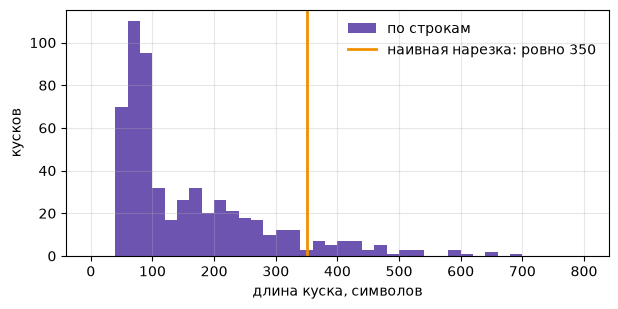

In [79]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist([len(c["text"]) for c in line_chunks], bins=40, range=(0, 800), color=COLORS["violet"], alpha=0.85, label="по строкам")
ax.axvline(350, color=COLORS["amber"], lw=2, label="наивная нарезка: ровно 350")
ax.set_xlabel("длина куска, символов"); ax.set_ylabel("кусков"); ax.legend(frameon=False); ax.grid(alpha=0.3);

In [80]:
EMB = {}

def load_cache():
    for path in [DATA / "embeddings_512.npz", Path("emb_cache.npz")]:
        if path.exists():
            z = np.load(path)
            EMB.update({str(k): v.astype(np.float32) for k, v in zip(z["keys"], z["vectors"])})
    return len(EMB)

def save_cache():
    np.savez_compressed("emb_cache.npz", keys=np.array(list(EMB)), vectors=np.stack(list(EMB.values())).astype(np.float16))

def embed_batch(texts):
    started = time.perf_counter()
    data = post_with_retry(EMBED_URL, {"model": EMBED_MODEL, "input": texts, "dimensions": DIM})
    ledger.add("embed", EMBED_MODEL, data.get("usage") or {}, time.perf_counter() - started)
    return [row["embedding"] for row in data["data"]]

def key_of(text):
    return hashlib.sha1(text.encode("utf-8")).hexdigest()

load_cache()

963

In [81]:
def embed_cached(texts):
    missing = list(dict.fromkeys(t for t in texts if key_of(t) not in EMB))
    for i in range(0, len(missing), 64):
        batch = missing[i:i + 64]
        for text, vector in zip(batch, embed_batch(batch)):
            EMB[key_of(text)] = np.array(vector, dtype=np.float32)

    vectors = np.stack([EMB[key_of(t)] for t in texts])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)

In [82]:
def emb_text(chunk):
    return f"{chunk['page']}: {chunk['text']}"

line_vecs = embed_cached([emb_text(c) for c in line_chunks])
char_vecs = embed_cached([c["text"] for c in char_chunks])
q_vecs = embed_cached([t["question"] for t in tasks])
save_cache()
line_vecs.shape, char_vecs.shape, q_vecs.shape

((579, 512), (330, 512), (50, 512))

In [83]:
probe = embed_cached(["Who won F1 Chinese Grand Prix 2026?", "Which country became world champion in football in 2026?", "Kimi Antonelli"])
save_cache()
(probe @ probe.T).round(2), ledger.table()

(array([[1.  , 0.52, 0.21],
        [0.52, 1.  , 0.04],
        [0.21, 0.04, 1.  ]], dtype=float32),
                               calls  prompt  completion     cost
 tag   model                                                     
 embed text-embedding-3-small     19   64478           0  0.00129)

In [84]:
def search_numpy(query_vec, vectors, k=5):
    sims = vectors @ query_vec
    top = np.argsort(-sims)[:k]
    return [(int(i), float(sims[i])) for i in top]

In [85]:
NUMBERS = {word: str(n) for n, word in enumerate("zero one two three four five six seven eight nine ten eleven twelve".split())}

def norm(text):
    words = re.sub(r"\b(a|an|the)\b|[^\w\s]", " ", str(text).lower()).split()
    return " ".join(NUMBERS.get(w, w) for w in words)

def is_gold(chunk, task):
    if chunk["page"] != task["page"]:
        return False
    text, words = norm(chunk["text"]), norm(task["evidence"]).split()
    return norm(task["answer"]) in text and sum(w in text for w in words) >= 0.5 * len(words)

def recall_curve(chunks, vectors, ks=(1, 3, 5, 10, 20)):
    ranked = [[i for i, _ in search_numpy(q, vectors, max(ks))] for q in q_vecs]
    return {k: float(np.mean([any(is_gold(chunks[i], t) for i in r[:k]) for r, t in zip(ranked, tasks)])) for k in ks}

for i, score in search_numpy(q_vecs[0], line_vecs, 3):
    print(round(score, 3), "|", line_chunks[i]["page"], "|", line_chunks[i]["text"][:110])
tasks[0]["question"], tasks[0]["answer"]

0.633 | 2026 Race Results | Grand Prix | Date | Winner | Team | Laps | Time
0.626 | 2026 Race Results | Flag of Australia Australia | 08 Mar | George Russell RUS | Mercedes | 58 | 1:23:06.801
0.584 | Need to Know: 2026 Singapore Grand Prix | The Singapore Grand Prix will host Round 17 of the 2026 Formula 1 season this weekend, marking the last leg of


('Who won the 2026 Australian Grand Prix?', 'George Russell')

,по строкам,по 350 символов
1,0.58,0.30
3,0.84,0.38
5,0.88,0.52
10,0.94,0.74
20,0.98,0.94


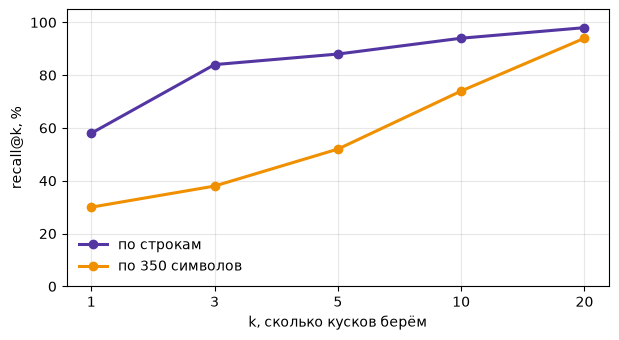

In [86]:
curves = {"по строкам": recall_curve(line_chunks, line_vecs), "по 350 символов": recall_curve(char_chunks, char_vecs)}
fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, curve), color in zip(curves.items(), [COLORS["violet"], COLORS["amber"]]):
    ax.plot([str(k) for k in curve], [v * 100 for v in curve.values()], marker="o", lw=2.2, color=color, label=name)
ax.set_xlabel("k, сколько кусков берём"); ax.set_ylabel("recall@k, %"); ax.set_ylim(0, 105); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig("img/recall.png", dpi=150, bbox_inches="tight")
pd.DataFrame(curves).round(2)

In [87]:
MILVUS_URI = os.getenv("MILVUS_URI", "http://localhost:19530")
client = MilvusClient(uri=MILVUS_URI, token=os.getenv("MILVUS_TOKEN", ""))
if os.getenv("MILVUS_DB"):
    if os.environ["MILVUS_DB"] not in client.list_databases():
        client.create_database(os.environ["MILVUS_DB"])
    client.use_database(os.environ["MILVUS_DB"])
client.get_server_version(), client.list_collections()

('2.6.24', ['lines'])

In [88]:
def index_to_milvus(name, chunks, vectors):
    if client.has_collection(name):
        client.drop_collection(name)
    client.create_collection(name, dimension=vectors.shape[1], metric_type="COSINE")
    rows = [{"id" : i, "vector" : v.tolist(), **c} for i, (v, c) in enumerate(zip(vectors, chunks))]
    for i in range(0, len(rows), 1000):
        client.insert(name, rows[i:i + 1000])

    client.flush(name)
    return client.get_collection_stats(name)

In [89]:
def search_milvus(name, query, k=5, flt=""):
    vector = embed_cached([query])[0].tolist()
    hits = client.search(name, data = [vector], limit=k, filter=flt, output_fields=["page", "section", "url", "text"])[0]

    return [{**h['entity'], "id" : h['id'], "score": round(h['distance'], 4)} for h in hits]


In [90]:
index_to_milvus("lines", line_chunks, line_vecs), client.describe_index("lines", "vector")

({'row_count': 579},
 {'index_type': 'AUTOINDEX',
  'metric_type': 'COSINE',
  'field_name': 'vector',
  'index_name': 'vector',
  'total_rows': 579,
  'indexed_rows': 579,
  'pending_index_rows': 0,
  'state': 'Finished'})

In [91]:
pd.DataFrame(search_milvus("lines", tasks[0]["question"], 3))[["score", "page", "section", "text"]]

,score,page,section,text
0,0.6333,2026 Race Results,,Grand Prix | Date | Winner | Team | Laps | Time
1,0.6257,2026 Race Results,,Flag of Australia Australia | 08 Mar | George ...
2,0.5842,Need to Know: 2026 Singapore Grand Prix,,The Singapore Grand Prix will host Round 17 of...


In [92]:
from_numpy = [[i for i, _ in search_numpy(q, line_vecs, 5)] for q in q_vecs]
from_milvus = [[h["id"] for h in hits] for hits in client.search("lines", data=q_vecs.tolist(), limit=5)]
overlap = float(np.mean([len(set(a) & set(b)) / 5 for a, b in zip(from_numpy, from_milvus)]))
round(overlap, 3), sum(a == b for a, b in zip(from_numpy, from_milvus)), len(q_vecs)

(1.0, 50, 50)

In [94]:
pd.DataFrame(search_milvus("lines", "Who won the 2026 Australian Grand Prix?", 5, 'page == "2026 Race Results"'))[["score", "page", "section", "text"]]

,score,page,section,text
0,0.6333,2026 Race Results,,Grand Prix | Date | Winner | Team | Laps | Time
1,0.6257,2026 Race Results,,Flag of Australia Australia | 08 Mar | George ...
2,0.5525,2026 Race Results,,Flag of Austria Austria | 28 Jun | George Russ...
3,0.4979,2026 Race Results,,Flag of Azerbaijan Azerbaijan | 26 Sep | Georg...
4,0.4900,2026 Race Results,,Flag of Singapore Singapore | 11 Oct | Max Ver...


{'numpy, перебор': 0.05,
 'Milvus, запрос на вызов': 2.71,
 'Milvus, сто запросов пачкой': 0.12}

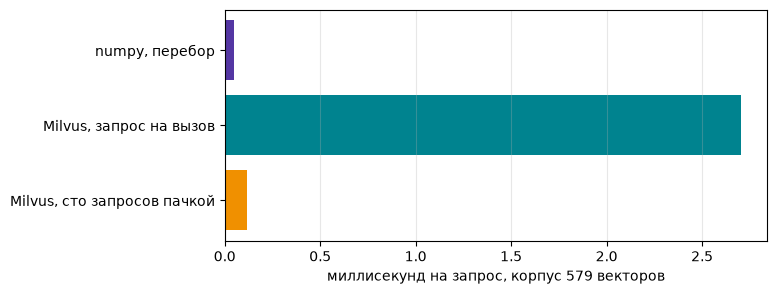

In [98]:
def per_query_ms(fn, n=100):
    started = time.perf_counter()
    fn()
    return (time.perf_counter() - started) * 1000 / n

queries = q_vecs[:100]
speed = {"numpy, перебор": per_query_ms(lambda: [search_numpy(q, line_vecs, 5) for q in queries], len(queries)),
         "Milvus, запрос на вызов": per_query_ms(lambda: [client.search("lines", data=[q.tolist()], limit=5) for q in queries], len(queries)),
         "Milvus, сто запросов пачкой": per_query_ms(lambda: client.search("lines", data=queries.tolist(), limit=5), len(queries))}
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(list(speed), list(speed.values()), color=[COLORS["violet"], COLORS["teal"], COLORS["amber"]])
ax.invert_yaxis(); ax.set_xlabel(f"миллисекунд на запрос, корпус {len(line_vecs)} векторов"); ax.grid(alpha=0.3, axis="x")
{name: round(ms, 2) for name, ms in speed.items()}

,"numpy, перебор","Milvus, запрос на вызов","Milvus, пачкой"
векторов,,,
579,0.11,1.95,0.23
50000,13.27,3.38,0.24
200000,42.69,2.55,0.27


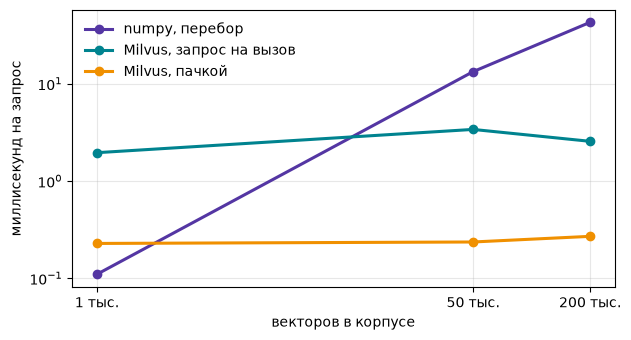

In [99]:
def inflate(vectors, n, noise=0.35, seed=0):
    rng = np.random.default_rng(seed)
    extra = vectors[rng.integers(0, len(vectors), n - len(vectors))]
    extra = extra + noise * rng.standard_normal(extra.shape, dtype=np.float32) / np.sqrt(vectors.shape[1])
    return np.vstack([vectors, extra / np.linalg.norm(extra, axis=1, keepdims=True)])

def wait_index(name, seconds=180):
    for _ in range(seconds):
        info = client.describe_index(name, "vector")
        if info.get("state") == "Finished" and info.get("pending_index_rows", 0) == 0:
            return True
        time.sleep(1)
    return False

scale_rows = []
for n in (len(line_vecs), 50_000, 200_000):
    big = inflate(line_vecs, n)
    if client.has_collection("scale"):
        client.drop_collection("scale")
    client.create_collection("scale", dimension=big.shape[1], metric_type="COSINE")
    for i in range(0, n, 5000):
        client.insert("scale", [{"id": i + j, "vector": v} for j, v in enumerate(big[i:i + 5000].tolist())])
    client.flush("scale")
    wait_index("scale")
    client.search("scale", data=[q_vecs[0].tolist()], limit=5)
    probe = q_vecs[:50]
    scale_rows.append({"векторов": n,
                       "numpy, перебор": per_query_ms(lambda: [search_numpy(q, big, 5) for q in probe], 50),
                       "Milvus, запрос на вызов": per_query_ms(lambda: [client.search("scale", data=[q.tolist()], limit=5) for q in probe], 50),
                       "Milvus, пачкой": per_query_ms(lambda: client.search("scale", data=probe.tolist(), limit=5), 50)})
client.drop_collection("scale")
scale = pd.DataFrame(scale_rows).set_index("векторов")
ax = scale.plot(figsize=(7, 3.6), marker="o", lw=2.2, logx=True, logy=True, color=[COLORS["violet"], COLORS["teal"], COLORS["amber"]])
ax.set_xticks(list(scale.index)); ax.set_xticklabels([f"{n / 1000:.0f} тыс." for n in scale.index]); ax.minorticks_off()
ax.set_ylabel("миллисекунд на запрос"); ax.set_xlabel("векторов в корпусе"); ax.legend(frameon=False); ax.grid(alpha=0.3)
ax.figure.savefig("img/scale.png", dpi=150, bbox_inches="tight")
scale.round(2)

In [100]:
RAG_SYSTEM = ("Answer the question using only the numbered sources. Cite the source number like [2]. "
              "If the sources do not contain the answer, reply exactly NOT_FOUND. The last line must be FINAL: <short answer>.")
PLAIN_SYSTEM = "Answer the question. If you do not know, reply NOT_FOUND. The last line must be FINAL: <short answer>."

In [101]:
def rag_answer(question, model, k=5, name="lines"):
    hits = search_milvus(name, question, k)
    sources = "\n".join(f"[{i + 1}] ({h['page']}) {h['text']}" for i, h in enumerate(hits))
    before = ledger.mine
    msg = chat([{"role": "system", "content": RAG_SYSTEM},
                {"role": "user", "content": f"Sources: {sources}\n\nQuestion:\n{question}"}], model, tag="rag")
    return {"answer" : msg.get("content") or "", "hits" : hits, "cost" : ledger.mine - before}


In [102]:
def plain_answer(question, model):
    before = ledger.mine
    msg = chat([{"role": "system", "content": PLAIN_SYSTEM}, {"role": "user", "content": question}], model, tag="plain")
    return {"answer": msg.get("content") or "", "hits": [], "cost": ledger.mine - before}

def final_answer(text):
    m = re.findall(r"FINAL:\s*(.+)", text or "")
    return m[-1].strip() if m else (text or "").strip()

def is_correct(task, answer):
    return f" {norm(task['answer'])} " in f" {norm(final_answer(answer))} "

def evaluate(fn, sample, config, model, workers=8):
    def one(task):
        try:
            out = fn(task["question"], model)
        except Exception as e:
            out = {"answer": f"ошибка: {e}", "hits": [], "cost": 0.0}
        return {"config": config, "model": model.split("/")[-1], "id": task["id"], "correct": is_correct(task, out["answer"]),
                "found": any(is_gold(h, task) for h in out["hits"]), "refused": "NOT_FOUND" in out["answer"],
                "cost": out["cost"], "answer": final_answer(out["answer"])[:60], "gold": task["answer"]}
    with ThreadPoolExecutor(workers) as pool:
        return pd.DataFrame(list(pool.map(one, sample)))

def report(results):
    g = results.groupby(["config", "model"], sort=False)
    table = g.agg(n=("correct", "size"), accuracy=("correct", "mean"), cost_per_task=("cost", "mean")).reset_index()
    table["cost_per_correct"] = table["cost_per_task"] / table["accuracy"].replace(0, float("nan"))
    return table.round(5)

def money_chart(table, path, baseline=None):
    fig, ax = plt.subplots(figsize=(8, 4.6))
    if baseline:
        ax.axhline(baseline[1] * 100, color=COLORS["grey"], ls="--", lw=1.2)
        ax.annotate(baseline[0], (0.01, baseline[1] * 100 + 1.5), xycoords=("axes fraction", "data"), fontsize=8, color=COLORS["grey"])
    for _, r in table.iterrows():
        color = COLORS["amber"] if "sonnet" in r["model"] else COLORS["teal"] if "haiku" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100), fontsize=8, xytext=(7, 3), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("цена вопроса, центы (логарифмическая шкала)"); ax.set_ylabel("доля верных, %"); ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

out = rag_answer(tasks[0]["question"], MODELS["cheap"])
print(out["answer"], "| эталон:", tasks[0]["answer"], "| цена, центов:", round(out["cost"] * 100, 4))

George Russell won the 2026 Australian Grand Prix [2]. 

FINAL: George Russell. | эталон: George Russell | цена, центов: 0.0059


In [104]:
sample = tasks
results = pd.concat([
    evaluate(plain_answer, sample, "без RAG", MODELS["cheap"]),
    evaluate(plain_answer, sample, "без RAG", MODELS["strong"]),
    evaluate(rag_answer, sample, "RAG, k=5", MODELS["cheap"]),
    evaluate(rag_answer, sample, "RAG, k=5", MODELS["mid"]),
    evaluate(rag_answer, sample, "RAG, k=5", MODELS["strong"]),
], ignore_index=True)
table = report(results)
table

,config,model,n,accuracy,cost_per_task,cost_per_correct
0,без RAG,gpt-4o-mini,50,0.04,0.00001,0.00035
1,без RAG,claude-sonnet-4.6,50,0.10,0.00105,0.01047
2,"RAG, k=5",gpt-4o-mini,50,0.64,0.00006,0.00009
3,"RAG, k=5",claude-haiku-4.5,50,0.74,0.00068,0.00092
4,"RAG, k=5",claude-sonnet-4.6,50,0.84,0.00188,0.00224


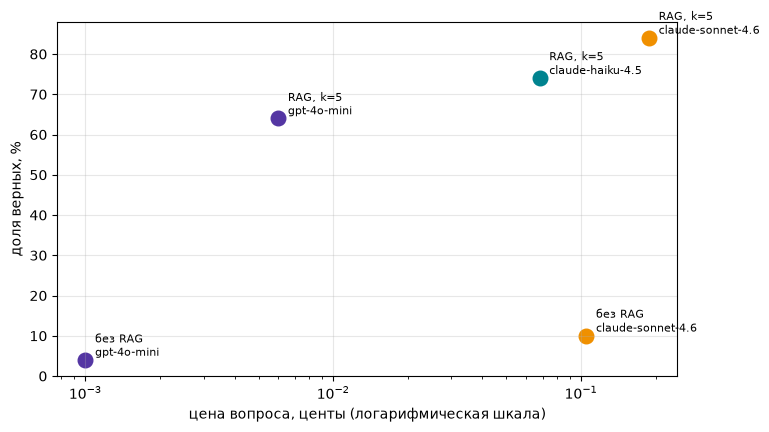

In [ ]:
money_chart(table, "img/money_rag.png");

,config,model,n,accuracy,cost_per_task,cost_per_correct
0,k=1,gpt-4o-mini,50,0.48,0.00003,0.00006
1,k=3,gpt-4o-mini,50,0.58,0.00004,0.00007
2,k=5,gpt-4o-mini,50,0.64,0.00006,0.00009
3,k=10,gpt-4o-mini,50,0.66,0.00009,0.00014


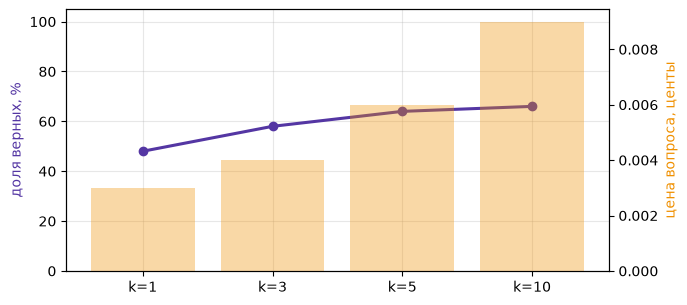

In [106]:
sweep = pd.concat([evaluate(lambda q, m, k=k: rag_answer(q, m, k), sample, f"k={k}", MODELS["cheap"]) for k in (1, 3, 5, 10)], ignore_index=True)
sweep_table = report(sweep)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(sweep_table["config"], sweep_table["accuracy"] * 100, marker="o", lw=2.2, color=COLORS["violet"]); ax.set_ylabel("доля верных, %", color=COLORS["violet"])
ax2 = ax.twinx(); ax2.bar(sweep_table["config"], sweep_table["cost_per_task"] * 100, alpha=0.35, color=COLORS["amber"]); ax2.set_ylabel("цена вопроса, центы", color=COLORS["amber"])
ax.set_ylim(0, 105); ax.grid(alpha=0.3)
sweep_table

In [107]:
def diagnose(results):
    wrong = results[~results["correct"] & results["config"].str.startswith("RAG")]
    return wrong.groupby("model").agg(не_нашли=("found", lambda s: int((~s).sum())), нашли_но_ответ_неверный=("found", "sum"))

diagnose(results)

,не_нашли,нашли_но_ответ_неверный
model,,
claude-haiku-4.5,6,7
claude-sonnet-4.6,6,2
gpt-4o-mini,6,12


In [108]:
results[~results["correct"] & (results["config"] == "RAG, k=5")][["model", "gold", "answer", "found"]]

,model,gold,answer,found
101,gpt-4o-mini,Kimi Antonelli,NOT_FOUND,False
106,gpt-4o-mini,Lewis Hamilton,NOT_FOUND.,False
114,gpt-4o-mini,Oscar Piastri,NOT_FOUND,True
115,gpt-4o-mini,Charles Leclerc,NOT_FOUND.,True
123,gpt-4o-mini,Kimi Antonelli,Lewis Hamilton.,False
126,gpt-4o-mini,Max Verstappen,NOT_FOUND.,False
131,gpt-4o-mini,luther,NOT_FOUND,True
132,gpt-4o-mini,DeBÍ TiRAR MáS FOToS,NOT_FOUND.,False
133,gpt-4o-mini,WILDFLOWER,NOT_FOUND,True
134,gpt-4o-mini,Olivia Dean,NOT_FOUND.,True


In [109]:
def tokens(text):
    return re.findall(r"\w+", text.lower())

def build_keyword_index(texts):
    docs = [set(tokens(text)) for text in texts]
    df = {}
    for d in docs:
        for w in d:
            df[w] = df.get(w, 0) + 1
    return docs, {w: np.log(len(docs) / n) for w, n in df.items()}

def keyword_search(query, docs, idf, k=20):
    q = set(tokens(query))
    scores = np.array([sum(idf.get(w, 0.0) for w in q & d) for d in docs])
    return [int(i) for i in np.argsort(-scores)[:k]]

In [114]:
def rrf(rankings, k=5, K=60):
    scores = {}
    for ranking in rankings:
        for rank, idx in enumerate(ranking):
            scores[idx] = scores.get(idx, 0.0) + 1 / (K + rank + 1)

    return sorted(scores, key=scores.get, reverse=True)[:k]


,нарезка,поиск,recall@1,recall@5
0,по 400 символов,только вектор,0.30,0.52
1,по 400 символов,только слова,0.30,0.40
2,по 400 символов,гибрид RRF,0.32,0.50
3,по строкам,только вектор,0.58,0.88
4,по строкам,только слова,0.24,0.44
5,по строкам,гибрид RRF,0.42,0.70


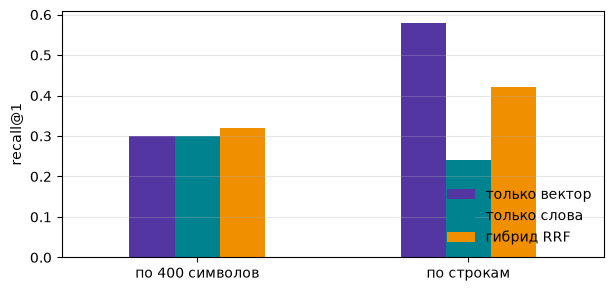

In [115]:
def recall_of(rankings, chunks, k=5):
    return float(np.mean([any(is_gold(chunks[i], t) for i in r[:k]) for r, t in zip(rankings, tasks)]))

rows = []
for cut, chunks, vectors, texts in [("по 400 символов", char_chunks, char_vecs, [c["text"] for c in char_chunks]),
                                    ("по строкам", line_chunks, line_vecs, [emb_text(c) for c in line_chunks])]:
    docs, idf = build_keyword_index(texts)
    by_vector = [[i for i, _ in search_numpy(q, vectors, 20)] for q in q_vecs]
    by_words = [keyword_search(t["question"], docs, idf, 20) for t in tasks]
    by_hybrid = [rrf([v, w], 20) for v, w in zip(by_vector, by_words)]
    rows += [{"нарезка": cut, "поиск": name, "recall@1": recall_of(r, chunks, 1), "recall@5": recall_of(r, chunks, 5)}
             for name, r in [("только вектор", by_vector), ("только слова", by_words), ("гибрид RRF", by_hybrid)]]
hybrid = pd.DataFrame(rows).round(2)
ax = hybrid.pivot(index="нарезка", columns="поиск", values="recall@1")[["только вектор", "только слова", "гибрид RRF"]].plot.bar(
    figsize=(7, 3.2), color=[COLORS["violet"], COLORS["teal"], COLORS["amber"]], rot=0)
ax.set_ylabel("recall@1"); ax.set_xlabel(""); ax.legend(frameon=False, loc="lower right"); ax.grid(alpha=0.3, axis="y")
hybrid

In [117]:
UNANSWERABLE = [
    "What was George Russell's starting fuel load in kilograms at the 2026 Australian Grand Prix?",
    "What front tyre pressure in psi did Kimi Antonelli use at the start of the 2026 Chinese Grand Prix?",
    "What was Kimi Antonelli's average fuel consumption per lap at the 2026 Japanese Grand Prix?",
    "What was the exact duration of Lewis Hamilton's first pit stop at the 2026 Barcelona-Catalunya Grand Prix?",
    "What rear wing angle in degrees did Max Verstappen use at the 2026 Bahrain Grand Prix?",
    "What was the humidity percentage at the start of the 2026 Singapore Grand Prix?",
    "What was the wind speed at kickoff in the 2026 FIFA World Cup final between Spain and Argentina?",
    "What was Bukayo Saka's maximum running speed during the 2026 FIFA World Cup bronze final?",
    "What was the humidity percentage inside the stadium at kickoff in Super Bowl LX?",
    "How many voting ballots did Olivia Dean receive to win Best New Artist at the 2026 Grammy Awards?",
]

refusals = [rag_answer(q, MODELS["cheap"]) for q in UNANSWERABLE]
sum("NOT_FOUND" in r["answer"] for r in refusals), [final_answer(r["answer"])[:40] for r in refusals if "NOT_FOUND" not in r["answer"]]

(10, [])

(0.657, 0.609)

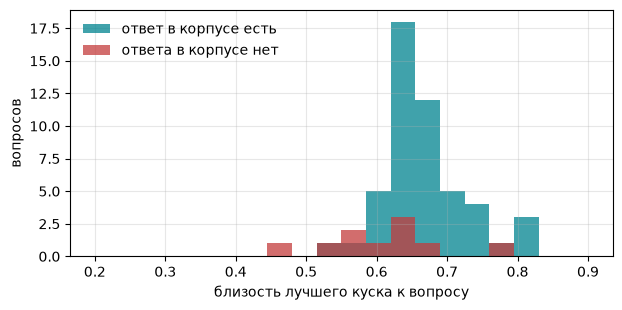

In [118]:
top_answerable = [search_numpy(q, line_vecs, 1)[0][1] for q in q_vecs]
top_unanswerable = [r["hits"][0]["score"] for r in refusals]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(top_answerable, bins=20, range=(0.2, 0.9), alpha=0.75, color=COLORS["teal"], label="ответ в корпусе есть")
ax.hist(top_unanswerable, bins=20, range=(0.2, 0.9), alpha=0.75, color=COLORS["red"], label="ответа в корпусе нет")
ax.set_xlabel("близость лучшего куска к вопросу"); ax.set_ylabel("вопросов"); ax.legend(frameon=False); ax.grid(alpha=0.3)
round(float(np.median(top_answerable)), 3), round(float(np.median(top_unanswerable)), 3)

In [140]:
answered = results[(results["config"] == "RAG, k=5") & (results["model"] == "gpt-4o-mini")]
pd.DataFrame([{"конфигурация": "RAG, gpt-4o-mini, k=5", "честные отказы из 10": sum("NOT_FOUND" in r["answer"] for r in refusals), 
               "ошибочные отказы из 50": int(answered["refused"].sum())}])

,конфигурация,честные отказы из 10,ошибочные отказы из 50
0,"RAG, gpt-4o-mini, k=5",10,19


In [119]:
FACTS_SYSTEM = ("Ты ведёшь память ассистента о пользователе. Верни один JSON-объект вида {\"facts\": [\"...\"]}: полный обновлённый список "
                "коротких фактов о пользователе. Добавь новые устойчивые факты: имя, город, работа, интересы, пожелания к ответам. "
                "Если новый факт отменяет старый, замени старый. Разовые вопросы и мелочи не записывай.")
ASSISTANT_SYSTEM = ("Ты помощник, который отвечает на вопросы о событиях 2026 года по базе знаний. Отвечай на языке пользователя, "
                    "опирайся на источники и на то, что знаешь о пользователе. Источники подобраны автоматически и могут быть не по теме: "
                    "используй только те, что относятся к вопросу. Если в источниках ответа нет, так и скажи.")
JOURNAL, FACTS_FILE = Path("episodes.jsonl"), Path("facts.json")

class Facts(BaseModel):
    facts: list[str] = Field(description="короткие факты о пользователе")

def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S)
    cleaned = re.sub(r'(\\["\\/bfnrtu])|\\', lambda e: e.group(1) or "\\\\", m.group(0) if m else "{}")
    return json.loads(cleaned, strict=False)

def known_facts():
    return json.loads(FACTS_FILE.read_text(encoding="utf-8")) if FACTS_FILE.exists() else []

def store_facts(facts):
    FACTS_FILE.write_text(json.dumps(facts, ensure_ascii=False, indent=1), encoding="utf-8")
    if facts:
        index_to_milvus("facts", [{"page": "memory", "section": "", "url": "", "text": f} for f in facts], embed_cached(facts))

def remember_episode(session, role, text):
    with JOURNAL.open("a", encoding="utf-8") as f:
        f.write(json.dumps({"session": session, "time": time.strftime("%Y-%m-%d %H:%M:%S"), "role": role, "text": text}, ensure_ascii=False) + "\n")

for path in (JOURNAL, FACTS_FILE):
    path.unlink(missing_ok=True)
if client.has_collection("facts"):
    client.drop_collection("facts")

In [124]:
def extract_facts(dialog, known):
    prompt = f"Известные факты: {json.dumps(known, ensure_ascii=False)}\n\nДиалог:\n{dialog}"
    msg = chat([{"role": "system", "content": FACTS_SYSTEM}, {"role": "user", "content": prompt}], MODELS["cheap"], tag="memory")
    return Facts.model_validate(json_from(msg.get("content"))).facts

In [125]:
def recall_facts(question, k=3):
    if not client.has_collection("facts"):
        return []
    return [h["text"] for h in search_milvus("facts", question, k)]


In [126]:
def search_with_memory(user_text, facts, k=5):
    plain = search_milvus("lines", user_text, k)
    personal = search_milvus("lines", user_text + " " + " ".join(facts), k) if facts else []
    by_id = {h["id"]: h for h in plain + personal}
    return [by_id[i] for i in rrf([[h["id"] for h in plain], [h["id"] for h in personal]], k)]

def talk(session, history, user_text, mode="память"):
    remember_episode(session, "user", user_text)
    facts = recall_facts(user_text) if mode == "память" else []
    hits = search_with_memory(user_text, facts) if "?" in user_text else []
    sources = "\n".join(f"[{i + 1}] ({h['page']}) {h['text']}" for i, h in enumerate(hits)) or "нет"
    system = ASSISTANT_SYSTEM + ("\nЧто известно о пользователе: " + "; ".join(facts) if facts else "")
    window = history[-4:] if mode == "память" else history
    msg = chat([{"role": "system", "content": system}] + window + [{"role": "user", "content": f"Источники:\n{sources}\n\n{user_text}"}],
               MODELS["cheap"], tag=f"dialog: {mode}")
    answer = msg.get("content") or ""
    history += [{"role": "user", "content": user_text if mode == "память" else f"Источники:\n{sources}\n\n{user_text}"}, {"role": "assistant", "content": answer}]
    remember_episode(session, "assistant", answer)
    return answer

def end_session(history):
    dialog = "\n".join(f"{m['role']}: {m['content'][:400]}" for m in history)
    store_facts(extract_facts(dialog, known_facts()))
    return known_facts()

In [128]:
first = []
print(talk("s1", first, "Привет! Я Лена, продуктовый аналитик из Новосибирска. Слежу за космосом и хоккеем, отвечай коротко."))
print(talk("s1", first, "Что было в космосе в июле 2026 года?"))
end_session(first)

Привет, Лена! К сожалению, у меня нет информации о событиях 2026 года. Если у тебя есть конкретные вопросы, постараюсь помочь!
К сожалению, у меня нет информации о событиях в космосе в июле 2026 года. Если у тебя есть другие вопросы, дай знать!


['Имя: Лена',
 'Город: Новосибирск',
 'Работа: продуктовый аналитик',
 'Интересы: космос, хоккей',
 'Пожелания к ответам: отвечай коротко']

In [129]:
second = []
print(talk("s2", second, "Что интересного случилось в моих темах за лето?"))
print(talk("s2", second, "Хоккей я забросила, теперь слежу за футболом. И я переехала в Калининград."))
print(talk("s2", second, "Кто выиграл чемпионат мира по футболу?"))
end_session(second)

К сожалению, в предоставленных источниках нет информации о событиях в космосе или хоккее за лето 2026 года. Если у вас есть конкретные вопросы по этим темам, я постараюсь помочь!
Спасибо за обновление! К сожалению, у меня нет информации о событиях в футболе или других темах за лето 2026 года. Если у вас есть конкретные вопросы или интересные темы, которые вы хотели бы обсудить, дайте знать!
Чемпионат мира по футболу 2026 года выиграла Испания, которая одержала победу над Аргентиной со счетом 1-0 в дополнительное время. Это стало для Испании вторым титулом чемпиона мира.


['Имя: Лена',
 'Город: Калининград',
 'Работа: продуктовый аналитик',
 'Интересы: космос, футбол',
 'Пожелания к ответам: отвечай коротко']

,prompt,cost
tag,,
dialog: память,5721,0.00115
dialog: вся история,19444,0.00215


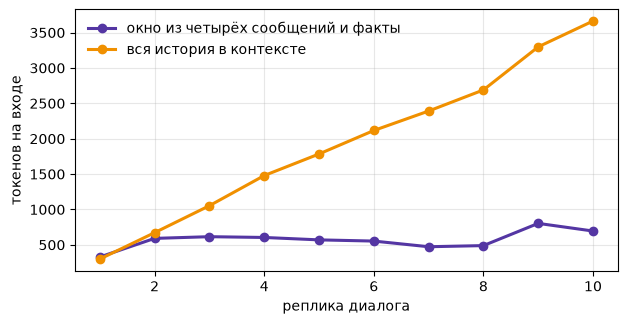

In [130]:
SCRIPT = [t["question"] for t in tasks[40:50]]
for mode in ("память", "вся история"):
    history = []
    for q in SCRIPT:
        talk("bench", history, q, mode)
per_turn = pd.DataFrame([c for c in ledger.calls if c["tag"].startswith("dialog: ")][-2 * len(SCRIPT):])
fig, ax = plt.subplots(figsize=(7, 3.4))
for (tag, part), color in zip(per_turn.groupby("tag", sort=False), [COLORS["violet"], COLORS["amber"]]):
    ax.plot(range(1, len(part) + 1), part["prompt"].values, marker="o", lw=2.2, color=color,
            label={"dialog: память": "окно из четырёх сообщений и факты", "dialog: вся история": "вся история в контексте"}[tag])
ax.set_xlabel("реплика диалога"); ax.set_ylabel("токенов на входе"); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig("img/memory_tokens.png", dpi=150, bbox_inches="tight")
per_turn.groupby("tag", sort=False).agg(prompt=("prompt", "sum"), cost=("cost", "sum")).round(5)

In [131]:
TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}

def run_tool(call):
    name = call["function"]["name"]
    try:
        spec = TOOLS[name]
        result = spec["fn"](**spec["args"].model_validate_json(call["function"]["arguments"]).model_dump())
    except Exception as e:
        result = f"ошибка инструмента {name}: {e}"
    return {"role": "tool", "tool_call_id": call["id"], "content": str(result)[:3000]}

AGENT_SYSTEM = ("You answer questions about events of 2026. Never answer from memory: look facts up with the tools, do not repeat the same call. "
                "When done, write the last line as FINAL: <short answer>, or NOT_FOUND if the knowledge base has no answer.")

def agent(question, model, max_steps=6):
    messages, seen, before = [{"role": "system", "content": AGENT_SYSTEM}, {"role": "user", "content": question}], set(), ledger.mine
    schemas = [t["schema"] for t in TOOLS.values()]
    for step in range(max_steps):
        msg = chat(messages, model, tools=schemas, tag="agent")
        messages.append(msg)
        calls = msg.get("tool_calls") or []
        keys = {(c["function"]["name"], c["function"]["arguments"]) for c in calls}
        if not calls or keys & seen or step == max_steps - 1:
            break
        seen |= keys
        messages += [run_tool(c) for c in calls]
    if calls:
        messages += [{"role": "tool", "tool_call_id": c["id"], "content": "call rejected: answer from what you already have"} for c in calls]
        msg = chat(messages, model, tag="agent")
    searches = sum(m.get("role") == "tool" for m in messages if isinstance(m, dict))
    return {"answer": msg.get("content") or "", "hits": [], "cost": ledger.mine - before, "searches": searches}

class KBArgs(BaseModel):
    query: str = Field(description="short search query in English: names, dates, key terms of the event")
    page: str = Field(default="", description="optional exact page title to search within, for example '2026 in Japan'; empty means all pages")

In [132]:
def knowledge_base(query: str, page: str = "") -> str:
    hits = search_milvus("lines", query, 5, f'page == "{page}"' if page else "")
    if not hits:
        return "NOTHING_FOUND"
    return "\n".join(f"[{i + 1}] ({h['page']}) / {h['section']} {h['text']}" for i, h in enumerate(hits))

In [133]:
register(knowledge_base, KBArgs, "Searches the local knowledge base of 2026 events and returns the five closest facts with their page and section")
out = agent(tasks[3]["question"], MODELS["cheap"])
print(out["answer"], "| эталон:", tasks[3]["answer"], "| обращений к базе:", out["searches"], "| цена, центов:", round(out["cost"] * 100, 4))

Kimi Antonelli won the 2026 Miami Grand Prix, driving for Mercedes. The race took place on May 3, 2026, and he completed it in a time of 1:33:19.273. 

FINAL: Kimi Antonelli | эталон: Kimi Antonelli | обращений к базе: 1 | цена, центов: 0.0138


,config,model,n,accuracy,cost_per_task,cost_per_correct
0,"RAG, k=5",gpt-4o-mini,50,0.64,0.00006,0.00009
1,агент с инструментом,gpt-4o-mini,50,0.88,0.00029,0.00033


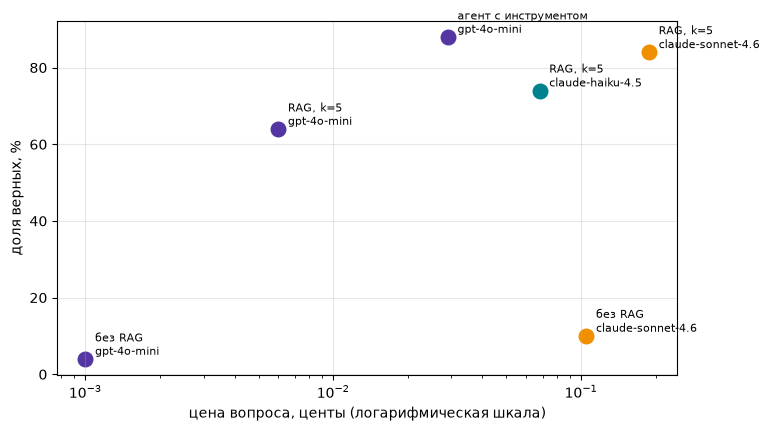

In [143]:
agent_results = evaluate(agent, sample, "агент с инструментом", MODELS["cheap"])
always = results[(results["config"] == "RAG, k=5") & (results["model"] == "gpt-4o-mini")]
final_table = report(pd.concat([results, agent_results], ignore_index=True))
last_week = float(np.mean([t["agent_ok"] for t in sample]))
money_chart(final_table, "img/money_all.png");
report(pd.concat([always, agent_results], ignore_index=True))

In [135]:
ledger.table(), round(ledger.total, 3)

(                                            calls  prompt  completion     cost
 tag                 model                                                     
 agent               gpt-4o-mini               150   80243        4087  0.01424
 dialog: вся история gpt-4o-mini                10   19444         397  0.00215
 dialog: память      gpt-4o-mini                17    9460         767  0.00188
 embed               text-embedding-3-small    147   66480           0  0.00133
 memory              gpt-4o-mini                 3     991         158  0.00024
 plain               claude-sonnet-4.6          50    2596        2972  0.05237
                     gpt-4o-mini                88    4442         978  0.00125
 rag                 claude-haiku-4.5           50   16239        3585  0.03416
                     claude-sonnet-4.6          50   16289        3011  0.09403
                     gpt-4o-mini               271   79482        5005  0.01493,
 0.217)

In [142]:
results[(results["config"] == "RAG, k=5") & (results["model"] == "claude-sonnet-4.6") & ~results["correct"]][["id", "gold", "answer", "found"]]

,id,gold,answer,found
201,custom-2026-01,Kimi Antonelli,NOT_FOUND,False
206,custom-2026-06,Lewis Hamilton,NOT_FOUND,False
223,custom-2026-23,Kimi Antonelli,Lewis Hamilton,False
226,custom-2026-26,Max Verstappen,NOT_FOUND,False
232,custom-2026-32,DeBÍ TiRAR MáS FOToS,NOT_FOUND,False
235,custom-2026-35,"Cynthia Erivo, Ariana Grande","Cynthia Erivo and Ariana Grande for ""Defying G...",True
245,custom-2026-45,Seattle Seahawks,NOT_FOUND,True
246,custom-2026-46,29-13,"Seattle 29, New England 13",False
